# NWB I/O

Read positions, identified spike trains, and acquisition windows from a real
NWB file on disk. Compute population rate maps, save an analysis copy, and
reopen it to verify the maps, support, units, identities, and settings.
The recording here is synthetic, so no download or private data is needed.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).

Install the optional NWB dependencies before running this notebook:
`uv sync --extra notebooks --extra nwb` from the repository root, then select
that environment's kernel. Array-only workflows do not require this extra.

In [1]:
import shutil
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

try:
    from pynwb import NWBHDF5IO, NWBFile
    from pynwb.behavior import Position, SpatialSeries
except ImportError as error:
    raise ImportError(
        "This notebook requires neurospatial[nwb]. In a checkout run "
        "`uv sync --extra notebooks --extra nwb`, then restart the kernel."
    ) from error

from neurospatial import Environment
from neurospatial.encoding import compute_spatial_rates
from neurospatial.io.nwb import (
    environment_from_position,
    read_place_field,
    read_position,
    read_units,
    write_spatial_rates,
)
from neurospatial.simulation import (
    PlaceCellModel,
    generate_poisson_spikes,
    simulate_trajectory_ou,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(10, 5))

## 1. Write a small source recording

Position and spikes share a clock in seconds. Tracking is available at 50 Hz;
electrophysiology has a 20 s gap. Observation intervals describe acquisition,
not whether a unit fired. Use the actual experiment's acquisition metadata
when constructing these windows; first and last spikes do not define coverage.

Units 7 and 42 are explicit synthetic labels. Independent random streams
generate the trajectory and each unit's spikes.

In [2]:
sim_env = Environment.from_grid_mask(
    np.ones((20, 20), dtype=bool),
    grid_edges=(np.arange(0, 105, 5.0), np.arange(0, 105, 5.0)),
)
sim_env.units = "cm"
positions, times = simulate_trajectory_ou(
    sim_env, duration=180.0, dt=0.02, speed_units="cm", speed_mean=15.0, seed=42
)
coverage = np.array([[times[0], 75.0], [95.0, times[-1]]])
unit_ids = np.array([7, 42])
spike_trains = []
for center, seed in [([40.0, 50.0], 142), ([60.0, 50.0], 143)]:
    model = PlaceCellModel(
        sim_env, center=center, width=12.0, max_rate=25.0, baseline_rate=0.5
    )
    spikes = generate_poisson_spikes(model.firing_rate(positions), times, seed=seed)
    observed = np.zeros(spikes.size, dtype=bool)
    for start, stop in coverage:
        observed |= (spikes >= start) & (spikes < stop)
    spike_trains.append(spikes[observed])

nwbfile = NWBFile(
    session_description="Synthetic recording for the neurospatial NWB workflow",
    identifier="neurospatial-synthetic-nwb-workflow",
    session_start_time=datetime(2026, 1, 1, tzinfo=timezone.utc),
)
tracking = Position(name="Position")
tracking.add_spatial_series(
    SpatialSeries(
        name="head_position",
        data=positions / 10.0,
        conversion=10.0,
        timestamps=times,
        unit="cm",
        reference_frame="Arena corner (0, 0)",
        description="Stored values times conversion give positions in centimeters",
    )
)
nwbfile.create_processing_module("behavior", "Behavioral tracking").add(tracking)
for unit_id, spikes in zip(unit_ids, spike_trains, strict=True):
    nwbfile.add_unit(id=int(unit_id), spike_times=spikes, obs_intervals=coverage)

temporary_data = tempfile.TemporaryDirectory(prefix="neurospatial-nwb-workflow-")
output_dir = Path(temporary_data.name)
source_path = output_dir / "source_recording.nwb"
analysis_path = output_dir / "recording_with_analysis.nwb"
with NWBHDF5IO(str(source_path), "w") as io:
    io.write(nwbfile)
print(
    f"Wrote {source_path.name}: {len(times):,} tracking samples, {len(unit_ids)} units"
)

Wrote source_recording.nwb: 9,000 tracking samples, 2 units


## 2. Read the disk file and inspect its metadata

Readers return named holders. Eager arrays are the default and remain usable
after closing the file. `lazy=True` handles require the source file to stay
open; lazy position reads also require identity conversion and offset.

`read_position` applies stored conversion and offset before reporting values
in `pos.units`. Unit aliases are normalized without rescaling the values.
`read_units` selects table identities, rather than row numbers, and exposes
the intersection of selected units' observation intervals as `spike_window`.

In [3]:
with NWBHDF5IO(str(source_path), "r") as io:
    recording = io.read()
    pos = read_position(
        recording, processing_module="behavior", position_name="head_position"
    )
    units = read_units(recording, unit_ids=[42, 7])  # deliberate label order
    if pos.units is None:
        raise ValueError("Resolve tracking units from the experiment before binning.")
    env = environment_from_position(
        recording,
        bin_size=5.0,
        units=pos.units,
        processing_module="behavior",
        position_name="head_position",
        frame="arena",
    )

np.testing.assert_allclose(pos.positions, positions)
np.testing.assert_array_equal(units.unit_ids, [42, 7])
np.testing.assert_array_equal(units.spike_window, coverage)
print(f"Position units: {pos.units}; selected unit order: {units.unit_ids.tolist()}")
print(f"Shared electrophysiology coverage:\n{units.spike_window}")

Position units: cm; selected unit order: [42, 7]
Shared electrophysiology coverage:
[[  0.    75.  ]
 [ 95.   179.98]]


## 3. Compute maps with explicit exposure and settings

`epochs` chooses the analyzed time range; `spike_window` describes acquisition.
The first/last 5 s and the recording gap are excluded from the analysis.
Tracking during an electrophysiology gap must not inflate the rate denominator.

This environment is inferred from the tracking extent. A known arena boundary
would be another defensible choice. Inspect occupancy and spatial support:
unobserved bins remain NaN rather than becoming zero firing rate.

         peak_rate  spatial_info  sparsity  grid_score  border_score  \
unit_id                                                                
42       19.886213      1.201405  0.282434   -0.013369      0.360978   
7        18.964255      1.081843  0.324225   -0.023730      0.106623   

            peak_x     peak_y cell_type  
unit_id                                  
42       59.991534  50.002717     place  
7        35.001361  50.002717     place  
Supported bins: 291 / 330


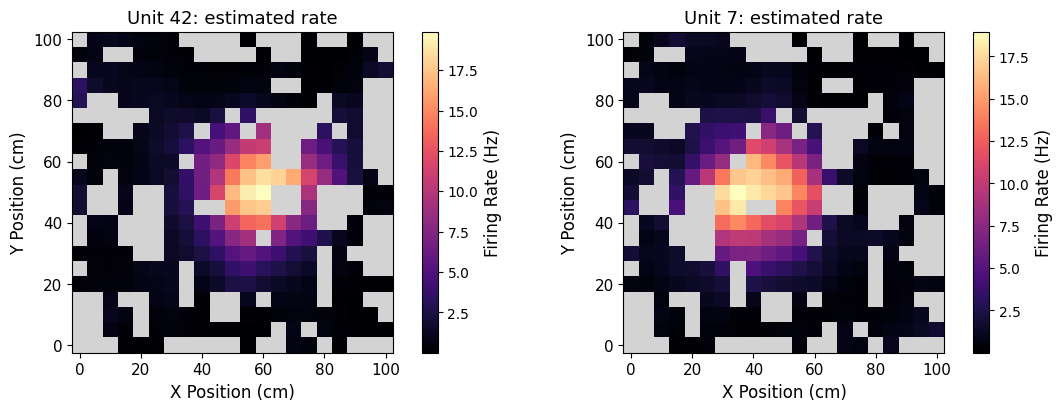

In [4]:
rates = compute_spatial_rates(
    env,
    units.spike_times,
    pos.times,
    pos.positions,
    unit_ids=units.unit_ids,
    epochs=[[5.0, times[-1] - 5.0]],
    spike_window=units.spike_window,
    bandwidth=6.0,
    min_occupancy=0.1,
)
print(rates.summary_table())
print(f"Supported bins: {rates.spatial_support.sum()} / {env.n_bins}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, unit_id in zip(axes, rates.unit_ids, strict=True):
    rates.sel(unit_id=int(unit_id)).plot(ax=ax, cmap="magma")
    ax.set_title(f"Unit {unit_id}: estimated rate")
plt.show()

## 4. Save an analysis copy and reopen it

`write_spatial_rates` stores maps, occupancy, identities, spatial support,
analysis settings, and a companion environment. `read_place_field` reconstructs
the population result despite its singular name. The lower-level
`write_place_field` array writer does not preserve this complete provenance.

Writers modify an in-memory NWBFile; `io.write` persists it. Here we copy the
source first and append to that fresh analysis copy. The source remains usable
independently. Choose a meaningful output location when adapting this workflow.

In [5]:
shutil.copy2(source_path, analysis_path)
with NWBHDF5IO(str(analysis_path), "a") as io:
    analysis_file = io.read()
    write_spatial_rates(analysis_file, rates, name="spatial_rates")
    io.write(analysis_file)

with NWBHDF5IO(str(analysis_path), "r") as io:
    restored = io.read()
    pos_back = read_position(restored, position_name="head_position")
    units_back = read_units(restored, unit_ids=[42, 7])
    rates_back = read_place_field(restored, name="spatial_rates")

# Eager holders and results are compared after closing the file.
np.testing.assert_allclose(pos_back.positions, pos.positions)
np.testing.assert_array_equal(units_back.unit_ids, units.unit_ids)
np.testing.assert_array_equal(units_back.spike_window, units.spike_window)
for train_back, train in zip(units_back.spike_times, units.spike_times, strict=True):
    np.testing.assert_array_equal(train_back, train)
np.testing.assert_allclose(rates_back.firing_rates, rates.firing_rates, equal_nan=True)
np.testing.assert_array_equal(rates_back.unit_ids, rates.unit_ids)
np.testing.assert_array_equal(rates_back.occupancy, rates.occupancy)
np.testing.assert_array_equal(rates_back.spatial_support, rates.spatial_support)
np.testing.assert_array_equal(rates_back.spike_window, rates.spike_window)
assert rates_back.analysis_settings == rates.analysis_settings
np.testing.assert_array_equal(rates_back.env.bin_centers, env.bin_centers)
assert set(rates_back.env.connectivity.edges) == set(env.connectivity.edges)
assert rates_back.env.units == env.units == pos_back.units == "cm"
outside = np.array([[-100.0, -100.0]])
np.testing.assert_array_equal(rates_back.env.bin_at(outside), env.bin_at(outside))
print(
    "Disk round trip verified: spike labels/coverage, maps, occupancy, support, settings, units."
)
print(
    f"Analysis copy: {analysis_path.name} ({analysis_path.stat().st_size / 1e6:.2f} MB)"
)

Disk round trip verified: spike labels/coverage, maps, occupancy, support, settings, units.
Analysis copy: recording_with_analysis.nwb (1.88 MB)


This checks a grid layout, including outside-point lookup. Other layouts may
reconstruct with different geometric capabilities; check the operations your
analysis requires after loading. For files containing ndx-pose or ndx-events,
import those extension packages before opening the file so registered types
are available. This example uses only core NWB containers.

The temporary files are removed below; all eager arrays remain available.
For related analyses, see [Peri-event analysis](07_peri_event_analysis.ipynb)
and [Real-data analysis](04_real_data_analysis.ipynb).

In [6]:
temporary_data.cleanup()